# Notebook 03 - Exploratory Data Analysis

**Input:** `data/processed/listings_clean.csv` (output of the cleaning phase)
**Output:** `data/processed/train.csv`, `data/processed/test.csv`, figures in `reports/figures/`

This notebook answers six questions and nothing else. Each section states the question,
shows the evidence, and ends with the decision it leads to. Those decisions become the
feature-engineering code in Notebook 04.

1. What does the target variable look like, and does it need a log transform?
2. Which numeric features carry signal, and are any of them redundant or leaky?
3. Which categorical features separate price, and which are too dirty to use as-is?
4. How should we represent locality?
5. What do we do about each block of missing values?
6. What gets dropped, and on what grounds?

**Deliberately skipped:** pairplots, a full 71x71 correlation heatmap, and a fresh outlier
hunt. The cleaning phase already set price and area bounds using domain knowledge, which is
a better instrument than a boxplot whisker.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 80)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

CLEAN = "../data/processed/listings_clean.csv"
FIG   = "../reports/figures/"
LAKH  = 1e5
CRORE = 1e7

## Load the cleaned data

In [2]:
df = pd.read_csv(CLEAN, low_memory=False)
print("rows, columns:", df.shape)

rows, columns: (19340, 71)


## Split before looking at anything

The split comes first, before a single statistic is computed. Every number from here on is
computed on the training set only.

The reason is that EDA is not passive. We are about to choose imputation values, category
groupings and a drop list from what we see. If we look at all 19,340 rows first, those
choices quietly carry information from the test rows into the model, and the test score stops
being an honest estimate of performance on listings the model has never seen.

An 80/20 split with a fixed `random_state` gives roughly 15,500 training rows - plenty for
these models - and 3,900 held-out rows, enough that the final metrics are stable.

We do **not** stratify on price. The cleaning report flagged that the scrape was organised by
price band, so the price distribution reflects how many pages each band offered rather than
the Hyderabad market. A plain random split is the honest choice here.

In [3]:
train, test = train_test_split(df, test_size=0.2, random_state=42)

train.to_csv("../data/processed/train.csv", index=False)
test.to_csv("../data/processed/test.csv", index=False)

print("train:", train.shape)
print("test :", test.shape)

train: (15472, 71)
test : (3868, 71)


---
# Q1. The target variable

Linear and Ridge Regression minimise *squared* error. If a handful of listings are ten times
the typical price, their squared errors dominate the loss, and the model spends its capacity
fitting mansions instead of the flats that make up most of the data. The usual remedy is to
train on `log(price)`. We measure the skew first, instead of assuming it.

Skew near 0 means symmetric. Above about 1 means meaningfully right-skewed.

Price in lakh:
count    15472.0
mean       200.2
std        210.5
min          1.4
1%          26.0
5%          45.0
25%         94.0
50%        150.0
75%        225.0
95%        525.0
99%       1000.0
max       4900.0
Name: price, dtype: float64

skew, raw price : 5.82
skew, log price : 0.09


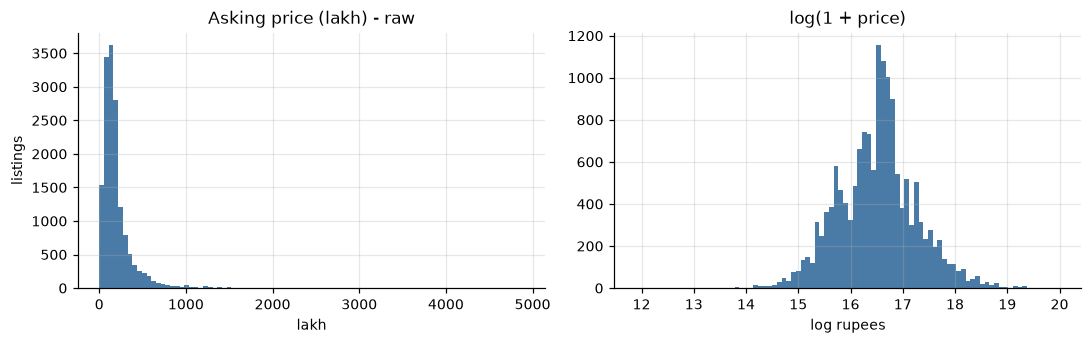

In [4]:
price = train["price"]

print("Price in lakh:")
print((price / LAKH).describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1))
print()
print("skew, raw price :", round(price.skew(), 2))
print("skew, log price :", round(np.log1p(price).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(price / LAKH, bins=90, color="#4a7ba7")
ax[0].set(title="Asking price (lakh) - raw", xlabel="lakh", ylabel="listings")
ax[1].hist(np.log1p(price), bins=90, color="#4a7ba7")
ax[1].set(title="log(1 + price)", xlabel="log rupees")
plt.tight_layout()
plt.savefig(FIG + "01_target_distribution.png", bbox_inches="tight")
plt.show()

### What this shows

The raw distribution has a skew of **5.82** - extreme. The median is about Rs 1.5 crore, but the
maximum is Rs 49 crore, so a long thin tail of expensive listings sits far above a dense cluster.
Logging the target brings the skew to **0.09**, essentially symmetric and close to bell-shaped.

**Decision.** Train every model on `log1p(price)`. Convert predictions back with `expm1`
before scoring, so that MAE and RMSE stay in rupees and remain explainable to a human
("typically off by Rs X lakh"). R-squared is reported on the log scale, because that is the
scale the model actually optimised.

---
# Q2. Numeric features

Two things to establish: which numeric columns relate to price, and whether any of them are
redundant or leaky. We correlate against **log price**, since that is the target we will model.

In [5]:
num = train.select_dtypes("number").drop(columns=["property_id", "locality_id", "zip_code"])
corr = num.assign(log_price=np.log1p(train["price"])).corr(numeric_only=True)["log_price"]
corr = corr.drop(["log_price", "price"]).sort_values(key=abs, ascending=False)

print("Correlation with log(price), strongest 18:")
print(corr.head(18).round(3).to_string())

Correlation with log(price), strongest 18:
covered_area             0.670
price_per_sqft_true      0.670
bathrooms                0.535
bedrooms                 0.511
carpet_area              0.490
balconies                0.341
avg_price_lmt            0.337
avg_price_sqft           0.311
total_floors             0.292
floor                    0.227
locality_rank           -0.192
locality_long           -0.179
price_quarter_current    0.176
longitude               -0.173
price_quarter_prev       0.172
rating_users_count       0.101
review_count             0.096
latitude                -0.089


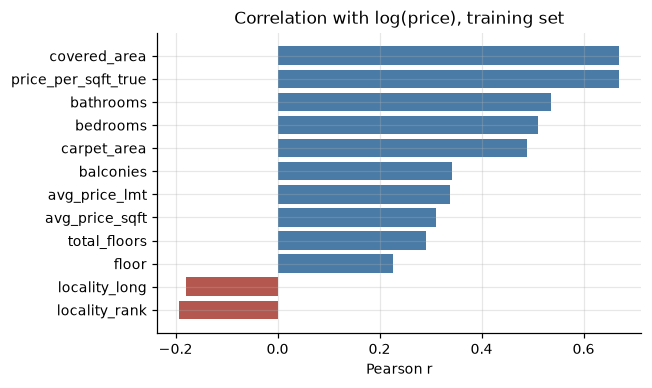

In [6]:
top = corr.head(12).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.barh(top.index, top.values, color=["#b4584f" if v < 0 else "#4a7ba7" for v in top.values])
ax.set(title="Correlation with log(price), training set", xlabel="Pearson r")
plt.tight_layout()
plt.savefig(FIG + "02_numeric_correlation.png", bbox_inches="tight")
plt.show()

### The leak hiding in plain sight

`price_per_sqft_true` scores 0.67, tied for the strongest feature in the table. It is
`price / covered_area` - the target divided by a feature. The cleaning phase correctly dropped
the site's `price_per_sqft`, but this column is the same quantity under a new name.

Let us confirm it rather than assert it.

In [7]:
check = (train["price"] / train["covered_area"]) / train["price_per_sqft_true"]
print("ratio of price/area to price_per_sqft_true:")
print(check.describe().round(4).to_string())
print()
print("rows where the ratio is not 1 (within 1%):", (check.sub(1).abs() > 0.01).sum())

ratio of price/area to price_per_sqft_true:
count    14275.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0

rows where the ratio is not 1 (within 1%): 0


The ratio is 1 on every row where area exists. It is arithmetic on the target, not a
measurement of the property. **It must be dropped.** Left in, it would produce an R-squared
above 0.95 and a model that cannot predict anything, because at prediction time you do not know
the price per square foot of a house whose price you are trying to predict.

Now the features that are genuinely useful.

In [8]:
cols = ["covered_area", "carpet_area", "bedrooms", "bathrooms", "balconies", "floor", "total_floors"]
print(train[cols].describe(percentiles=[.01, .5, .99]).round(1).to_string())
print()
print("missing %:")
print((train[cols].isna().mean() * 100).round(1).to_string())

       covered_area  carpet_area  bedrooms  bathrooms  balconies    floor  total_floors
count       14275.0       7875.0   15472.0    15398.0    10677.0  11077.0       11070.0
mean         2154.7       1943.7       3.3        3.2        2.0      5.6          11.0
std          1509.3       1848.9       1.6        1.6        1.1      7.2          11.7
min           200.0          1.0       1.0        1.0        1.0     -2.0           1.0
1%            561.5        200.0       1.0        1.0        1.0      0.0           1.0
50%          1750.0       1510.0       3.0        3.0        2.0      3.0           5.0
99%          8100.0       8000.0      11.0       11.0        6.0     33.0          47.3
max         20000.0      90000.0      11.0       11.0       11.0     63.0         101.0

missing %:
covered_area     7.7
carpet_area     49.1
bedrooms         0.0
bathrooms        0.5
balconies       31.0
floor           28.4
total_floors    28.5


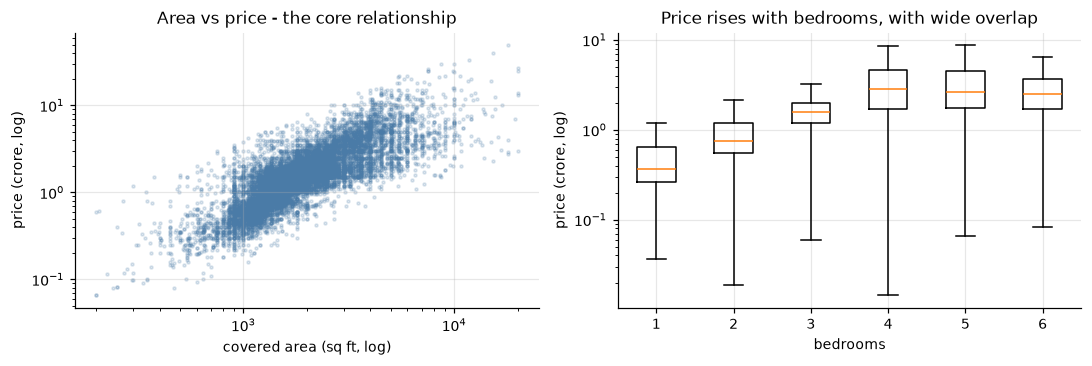

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))

ok = train["covered_area"].notna()
ax[0].scatter(train.loc[ok, "covered_area"], train.loc[ok, "price"] / CRORE,
              s=4, alpha=0.18, color="#4a7ba7")
ax[0].set(xscale="log", yscale="log", xlabel="covered area (sq ft, log)",
          ylabel="price (crore, log)", title="Area vs price - the core relationship")

bd = train[train["bedrooms"].between(1, 6)]
groups = [bd.loc[bd["bedrooms"] == b, "price"] / CRORE for b in range(1, 7)]
ax[1].boxplot(groups, tick_labels=[str(b) for b in range(1, 7)], showfliers=False)
ax[1].set(yscale="log", xlabel="bedrooms", ylabel="price (crore, log)",
          title="Price rises with bedrooms, with wide overlap")

plt.tight_layout()
plt.savefig(FIG + "03_area_bedrooms.png", bbox_inches="tight")
plt.show()

### What this shows

On a log-log scale, area against price is close to a straight line - the clean, almost linear
relationship that makes a logged target work well. Area is the single strongest honest
predictor (r = 0.67).

Bedrooms rise with price but the boxes overlap heavily: a 3-BHK in Kondapur and a 3-BHK on the
outskirts are the same room count at very different prices. Location has to do that work.

Three specific observations from the tables:

- **`bedrooms` maxes at 11.** The cleaning phase mapped the website's censored bucket
  ">10" to 11. It is not literally eleven bedrooms; it means "more than ten". Keeping it as a
  number preserves the ordering, which is the useful part.
- **`carpet_area` is 49% missing** and correlates 0.49 with log price - weaker than
  `covered_area` (0.67), which is 92% populated and measures nearly the same thing.
  Carrying a half-empty duplicate of a better column adds imputation noise for no gain.
- **`floor` and `total_floors` are each about 28% missing**, mostly on independent houses and
  villas, where "floor number" is not a meaningful question. The missingness is informative,
  not random.

### Is the missingness in `floor` really about house type?

That was a claim, so it needs a check rather than an assertion. If floor is missing because
"which floor" is a meaningless question for a standalone building, the missing rate should be
near zero for apartments and near total for villas.

In [10]:
fm = train.groupby("property_type")["floor"].apply(lambda s: s.isna().mean() * 100).round(1)
print("floor missing %, by property type:")
print(fm.to_string())

floor missing %, by property type:
property_type
Apartment                   4.6
Builder Floor Apartment     5.0
Penthouse                   0.0
Residential House          50.6
Villa                      99.9


Confirmed, and strongly: **99.9% of villas and 50.6% of houses have no floor number, against
4.6% of apartments.** This is not random missingness - it is a fact about the building type,
leaking in through an empty cell. A missing-indicator column will therefore carry real signal,
which is exactly why we pair every numeric imputation with one.

---
# Q3. Categorical features

For each candidate: how many levels, how the rows are spread across them, and whether median
price actually differs between levels. A categorical feature is useful when levels separate
price and each level has enough rows to estimate it.

In [11]:
def profile(col, n=8):
    s = train[col]
    counts = s.value_counts(dropna=False).head(n)
    med = (train.groupby(col, dropna=False)["price"].median() / LAKH).round(0)
    out = pd.DataFrame({"rows": counts, "median_price_lakh": med.reindex(counts.index)})
    print(f"--- {col} | {s.nunique()} levels | {s.isna().mean()*100:.1f}% missing ---")
    print(out.to_string())
    print()

for c in ["property_type", "transaction_type", "furnishing", "posted_by",
          "prime_location", "age_of_property"]:
    profile(c)

--- property_type | 5 levels | 0.0% missing ---
                         rows  median_price_lakh
property_type                                   
Apartment                8997              129.0
Residential House        4010              170.0
Villa                    1927              280.0
Builder Floor Apartment   503               75.0
Penthouse                  35              105.0

--- transaction_type | 3 levels | 0.2% missing ---
                   rows  median_price_lakh
transaction_type                          
Resale            13353              150.0
New Property       2049              164.0
Other                43              165.0
NaN                  27              200.0

--- furnishing | 3 levels | 2.0% missing ---
                rows  median_price_lakh
furnishing                             
Unfurnished     7549              150.0
Semi-Furnished  4768              150.0
Furnished       2848              160.0
NaN              307               75.0

--- posted_b

### Reading the table

- **`property_type` is the clear winner.** Median price runs from Rs 75 lakh (builder floor) to
  Rs 1.29 crore (apartment) to Rs 2.80 crore (villa). Five levels, all well populated. Keep.
- **`transaction_type`** - Resale 13,353 vs New Property 2,049, with a modest price gap. Cheap
  to include. Keep.
- **`furnishing`** separates only weakly (Rs 1.60 crore furnished vs Rs 1.50 crore unfurnished).
  It costs two columns. Keep, but do not expect much.
- **`posted_by`** - agents list higher-priced property than owners (Rs 1.80 vs Rs 1.50 crore).
  A plausible signal about which end of the market a listing comes from. Keep.
- **`prime_location`** is a flag the site sets: Rs 1.55 crore vs Rs 1.50 crore. Almost no
  separation, but it is one column. Keep.
- **`age_of_property`** is 36% missing and, revealingly, has almost no monotonic price pattern -
  "Above 20 years" has the *highest* median, because old property in central Hyderabad sits on
  expensive land. Keep with an explicit "Unknown" level rather than guessing an age.

Now two columns that look usable and are not.

In [12]:
print("--- facing: the top 12 values ---")
print(train["facing"].value_counts(dropna=False).head(12).to_string())

DIRECTIONS = ["East", "West", "North", "South",
              "North - East", "North - West", "South - East", "South - West"]
f = train["facing"]
print()
print("real compass directions :", f.isin(DIRECTIONS).sum())
print("free text / junk        :", (f.notna() & ~f.isin(DIRECTIONS)).sum())
print("missing                 :", f.isna().sum())

--- facing: the top 12 values ---
facing
NaN                                                                 6066
East                                                                4449
West                                                                2629
North                                                                940
North - East                                                         614
South                                                                292
Newly Constructed Property                                           176
North - West                                                         125
South - East                                                         102
South -West                                                           54
Near mohammedia masjid                                                 1
Opp to SLN Terminus, 10 mins walk to Botanical Gardens  AMB Mall       1

real compass directions : 9151
free text / junk        : 255
missing              

In [13]:
print("--- possession:", train["possession"].nunique(), "levels ---")
print(train["possession"].value_counts(dropna=False).head(10).to_string())

--- possession: 48 levels ---
possession
Ready to Move         13816
Under Construction     1111
NaN                     272
Dec '26                  37
Dec '28                  24
Nov '29                  15
Ready To Move            14
Mar '31                  13
Jul '28                  12
Dec '29                  12


### Two columns that need repair, not dropping

**`facing`** has 34 "levels" because the field collected whatever sellers typed. Only 9,151 rows
match one of the eight compass directions exactly. The other 255 split into three different
problems, and they do **not** all deserve the same treatment:

- **176 rows say "Newly Constructed Property"** - an answer to a different question entirely,
  which belongs in "Unknown".
- **54 rows say `"South -West"`** - a real direction with a missing space. pandas treats it as a
  separate category from `"South - West"`. Throwing these away would discard 54 perfectly good
  observations, so we **normalise the spacing** instead of binning them as unknown.
- **~25 rows are landmark text**: *"Near Nallakunta PS. Beside Jyothi Bala Mandir High School"*.
  One-hot encoding these creates a column per landmark, each matching a single property, each
  pure noise. These go to "Unknown".

Fix: collapse whitespace, keep the eight real directions, send the rest to "Unknown".

**`possession`** has 48 levels, but 13,830 of 15,472 rows are "Ready to Move" and 1,111 are
"Under Construction". The rest are individual dates ("Dec '26", "Mar '31") plus a casing
variant, "Ready To Move", that pandas treats as a different category. Fix: collapse to three
levels - Ready to Move, Under Construction, Future dated - which also folds the casing bug away.

These two repairs are the only feature engineering in this project that creates new columns.
Everything else is imputation and encoding.

---
# Q4. How to represent locality

Location is the biggest driver of property price, and the hardest thing in this dataset to
encode. The cleaning report noted two columns at different granularity, so first, how many
distinct places are we dealing with?

In [14]:
for c in ["locality", "locality_name", "sub_locality", "project_name", "builder_name"]:
    vc = train[c].value_counts()
    big = vc[vc >= 20]
    print(f"{c:15s} levels={train[c].nunique():6d}  missing={train[c].isna().mean()*100:5.1f}%"
          f"  levels>=20rows={len(big):4d}  rows covered by those={big.sum()/len(train)*100:5.1f}%")

locality        levels=  2177  missing=  4.2%  levels>=20rows= 129  rows covered by those= 61.6%
locality_name   levels=  1767  missing=  7.1%  levels>=20rows= 127  rows covered by those= 61.4%
sub_locality    levels=  6599  missing= 44.9%  levels>=20rows=  19  rows covered by those=  3.5%
project_name    levels=  8876  missing=  0.0%  levels>=20rows=  28  rows covered by those=  8.7%


builder_name    levels= 10388  missing=  0.0%  levels>=20rows=  33  rows covered by those=  6.6%


2,177 distinct localities for 15,472 training rows - roughly seven listings per locality.
One-hot encoding that produces 2,177 mostly-empty columns, and any locality appearing once in
training is a column of noise. Only 129 localities have 20 or more listings, and together they
cover 62% of the data.

`project_name` and `builder_name` are worse: 8,876 and 10,388 levels, almost all unique. Those
are identifiers, not categories.

The alternative is already in the dataset. The `locality_ratings` table brought published,
area-level numbers - and the cleaning report established that these are published *before* any
individual listing exists, so they are available at prediction time and are not leakage.

In [15]:
loc_cols = ["avg_price_sqft", "avg_price_lmt", "locality_rank", "growth_quarterly_pct",
            "rating_overall", "latitude", "longitude", "review_count"]
lc = pd.DataFrame({
    "missing_%": (train[loc_cols].isna().mean() * 100).round(1),
    "corr_with_log_price": train[loc_cols].apply(
        lambda s: s.corr(np.log1p(train["price"]))).round(3)})
print(lc.to_string())

                      missing_%  corr_with_log_price
avg_price_sqft             22.6                0.311
avg_price_lmt              42.1                0.337
locality_rank              28.8               -0.192
growth_quarterly_pct       31.0                0.066
rating_overall              7.1                0.075
latitude                    7.1               -0.089
longitude                   7.1               -0.173
review_count                7.1                0.096


`avg_price_sqft` (the locality's published price per square foot) correlates 0.31 with log
price, `avg_price_lmt` 0.34, and `locality_rank` -0.19 - the minus sign is correct, since rank 1
is the best locality. Each of these is **one** column that works for every locality, including
localities the model never saw in training.

An important distinction for the write-up: this is *not* target encoding. Target encoding means
computing the average price of our own training rows per locality, which leaks the target and
must be fitted inside CV folds. These numbers come from the website, computed over the whole
market before we scraped anything.

**Tested rather than assumed.** We will verify this in Notebook 04 by running both encodings:
core features plus locality one-hot, versus core features plus these locality numbers.

---
# Q5. Missing values

Grouping by *cause* rather than by percentage. The right treatment follows from why the value
is absent - and "high percentage missing" is not by itself a reason to drop a column.

In [16]:
miss = (train.isna().mean() * 100).round(1)
miss = miss[miss > 0].sort_values(ascending=False)
print(f"{len(miss)} of {train.shape[1]} columns have missing values")
print()
print(miss.to_string())

60 of 71 columns have missing values

parking                   75.2
power_status              72.8
water_status              72.4
flooring_type             63.6
additional_rooms          57.7
lux_amen_desc             55.9
luxury_amenities          55.8
nonluxAmenMap             55.8
luxAmenMap                55.8
pros_2                    54.7
carpet_area               49.1
amenities                 45.0
sub_locality              44.9
introduction              44.5
cons_1                    43.7
pros_1                    43.2
avg_price_lmt             42.1
facing                    39.2
age_of_property           36.3
balconies                 31.0
price_quarter_prev        31.0
growth_quarterly_pct      31.0
price_quarter_current     31.0
locality_rank             28.8
total_floors              28.5
floor                     28.4
avg_price_sqft            22.6
listing_date              19.5
rating_users_count        17.0
covered_area               7.7
price_per_sqft_true        7.7
l

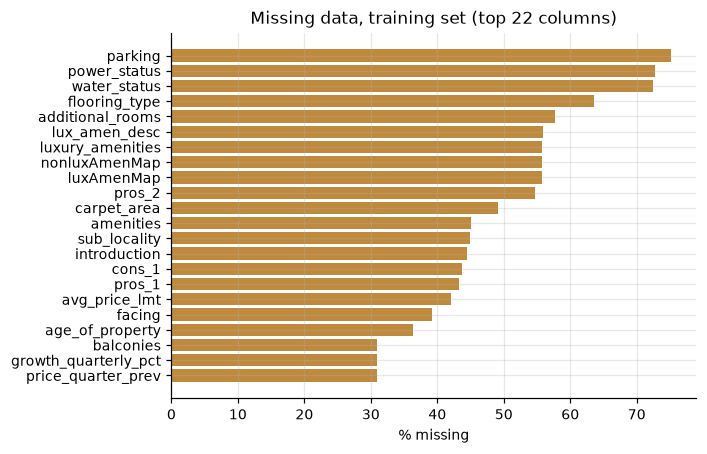

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
m = miss.head(22).sort_values()
ax.barh(m.index, m.values, color="#c08a3e")
ax.set(title="Missing data, training set (top 22 columns)", xlabel="% missing")
plt.tight_layout()
plt.savefig(FIG + "04_missingness.png", bbox_inches="tight")
plt.show()

### Decisions, by cause

| Block | Missing | Why it is missing | Decision |
|---|---|---|---|
| `covered_area` | 7.7% | seller left the field blank | **median impute + a "was missing" flag.** It is the strongest predictor, so losing 1,197 rows would hurt; and a model that knows the value was estimated can treat it differently. |
| `floor`, `total_floors` | 28% | independent houses and villas have no floor number | median impute + flag. The flag is the real feature: it partly identifies house-type property. |
| `balconies` | 31% | not stated, most likely means none | median impute + flag. |
| locality ratings, `avg_price_sqft` | 7-23% | the locality/ratings join found no match | median impute + flag. An unmatched locality is usually a small outlying one, which is itself information. |
| `facing` | 39% | not stated | encode as "Unknown" - a real category, not an error. |
| `age_of_property` | 36% | not stated | encode as "Unknown". |
| `carpet_area` | 49% | not stated | **drop the column.** Redundant with `covered_area`, which is better populated and more predictive. |
| `parking`, `power_status`, `water_status`, `flooring_type` | 73-75% | these are detail-page amenity fields, present only on richer listings | **drop for the baseline.** `flooring_type` has 182 comma-joined combinations ("Wooden,Marble,Granite") that would need string parsing, which this project is deliberately not doing yet. Noted as a future improvement. |

The principle worth stating: we never impute the target, we impute features. And every numeric
imputation is paired with a missing-indicator column, so the model can learn "area was blank"
as a fact in its own right instead of being told a median as if it were measured.

Critically, the median is computed **inside the pipeline**, which means it is computed from
training folds only. Computing it here, on the whole training set, and hardcoding the number
would leak across CV folds.

---
# Q6. The drop list

Each column is dropped for one of six stated reasons. Nothing is dropped because its name
looked unpromising.

In [18]:
drop_leakage    = ["price_per_sqft_true"]
drop_identifier = ["property_id", "locality_id", "zip_code", "project_name", "builder_name"]
drop_text       = ["property_title", "description", "amenities", "luxury_amenities",
                   "lux_amen_desc", "luxAmenMap", "nonluxAmenMap",
                   "introduction", "pros_1", "pros_2", "cons_1"]
drop_redundant  = ["carpet_area", "locality", "sub_locality", "locality_name",
                   "locality_lat", "locality_long", "price_quarter_current",
                   "price_quarter_prev", "listing_date", "possession", "facing"]
drop_sparse     = ["parking", "power_status", "water_status", "flooring_type",
                   "additional_rooms"]
drop_ratings    = [c for c in train.columns
                   if c.startswith("rating_") and c != "rating_overall"]

for name, cols in [("leakage", drop_leakage), ("identifiers", drop_identifier),
                   ("free text", drop_text), ("redundant", drop_redundant),
                   ("too sparse / needs parsing", drop_sparse),
                   ("individual ratings", drop_ratings)]:
    print(f"{name:28s} {len(cols):2d}  {cols}")

total = sum(len(c) for c in [drop_leakage, drop_identifier, drop_text,
                             drop_redundant, drop_sparse, drop_ratings])
print()
print(f"total dropped: {total} of {train.shape[1]} columns")

leakage                       1  ['price_per_sqft_true']
identifiers                   5  ['property_id', 'locality_id', 'zip_code', 'project_name', 'builder_name']
free text                    11  ['property_title', 'description', 'amenities', 'luxury_amenities', 'lux_amen_desc', 'luxAmenMap', 'nonluxAmenMap', 'introduction', 'pros_1', 'pros_2', 'cons_1']
redundant                    11  ['carpet_area', 'locality', 'sub_locality', 'locality_name', 'locality_lat', 'locality_long', 'price_quarter_current', 'price_quarter_prev', 'listing_date', 'possession', 'facing']
too sparse / needs parsing    5  ['parking', 'power_status', 'water_status', 'flooring_type', 'additional_rooms']
individual ratings           16  ['rating_safety', 'rating_cleanliness', 'rating_traffic', 'rating_connectivity', 'rating_environment', 'rating_school', 'rating_hospital', 'rating_users_count', 'rating_road', 'rating_neighbour', 'rating_transport', 'rating_parking', 'rating_restaurant', 'rating_market', 'rating_

### The reasoning, group by group

**Leakage (1).** `price_per_sqft_true` is the target divided by area. Proved above: the ratio
is 1 on every row that has an area.

**Identifiers (5).** `property_id` is a row name. `project_name` (8,876 levels) and
`builder_name` (10,388) are near-unique strings; one-hot encoding them would give the model a
lookup table of individual properties and teach it nothing that generalises.

**Free text (11).** The cleaning report found that 86% of `description` fields state the price
in words - *"this apartment is sold at price of Rs 46.9 Lac"*. Any text feature built on these
columns carries the answer. Using them safely requires stripping the price first, which is NLP
work this baseline is deliberately avoiding. `amenities` has 7,378 distinct comma-joined
strings and needs the same treatment.

**Redundant (11).** `locality_lat`/`locality_long` duplicate `latitude`/`longitude` after the
coordinate fallback. `price_quarter_current` and `price_quarter_prev` are the two numbers that
`growth_quarterly_pct` is computed from, so we keep the derived column and drop its inputs.
`locality`, `locality_name` and `sub_locality` are replaced by the locality aggregates, as
established in Q4. `possession` and `facing` are dropped in favour of the repaired versions
built in Notebook 04, not deleted outright.

**Too sparse or needs parsing (5).** 73-75% missing on detail-page-only amenity fields, and
`flooring_type` needs string splitting. Note this is a *judgement*, not a rule - the cleaning
phase deliberately kept these columns because missingness can be a signal, and we are setting
them aside for the baseline rather than destroying them. They are the most obvious thing to add
in version two.

**Individual ratings (16).** Sixteen columns (`rating_safety`, `rating_traffic`,
`rating_school` ...) that are all computed by the same website for the same locality and are
heavily correlated with each other. For linear models, sixteen collinear columns make the
coefficients unstable and uninterpretable. We keep `rating_overall` as the summary and let
`avg_price_sqft` and `locality_rank` carry the locality's market position.

---
# What Notebook 04 inherits

**Target:** `log1p(price)`, scored back in rupees.

**Numeric features (14)** - median imputed with missing-indicators, then standardised:
`covered_area`, `bedrooms`, `bathrooms`, `balconies`, `floor`, `total_floors`,
`avg_price_sqft`, `avg_price_lmt`, `locality_rank`, `growth_quarterly_pct`, `rating_overall`,
`review_count`, `latitude`, `longitude`.

**Categorical features (9)** - "Unknown" imputed, then one-hot encoded:
`property_type`, `transaction_type`, `furnishing`, `posted_by`, `prime_location`,
`age_of_property`, `possession_simple` (new), `facing_clean` (new), `coords_are_locality`.

**Dropped:** 49 columns in six justified groups.

**To verify in 04, not assume:** whether one-hot encoding the top localities beats the
published locality numbers.

Every imputation value, category list and scaling parameter will be learned inside a
scikit-learn `Pipeline`, so cross-validation refits them on each fold and the test set is
touched exactly once, at the very end.